# 7. Traffic simulation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/12_sim.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/12_sim.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You make the SUMO network of Monaco, read it with sumolib, run a short SUMO simulation, and join the counts of the simulation back to the duckOSM edges by `edge_id`. The module is `duckosm.sim`. [duckOSM for traffic simulation users](https://khoshkhah.github.io/duckOSM/compare/for-simulation-users/) compares each call with netconvert, sumolib and MATSim.

| Call | Result |
|---|---|
| `net.to_sumo` (`duckosm.sim.to_sumo`) | the SUMO network; the id of each SUMO edge is the `edge_id` |
| `duckosm.sim.sumo_net` | the network read with sumolib |
| `duckosm.sim.edge_map` | the SUMO or MATSim id → `edge_id`, to join the results back |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[sim,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
net                                                   # the card

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## The SUMO network

`to_sumo` writes SUMO's plain XML files and runs `netconvert` on them. The extra `sim` installs SUMO and sumolib.

In [3]:
files = net.driving.to_sumo("out/sumo")      # the plain XML files and network.net.xml
sn = duckosm.sim.sumo_net(files)             # the .net.xml read with sumolib
{"SUMO edges": len(sn.getEdges(withInternal=False)), "junctions": len(sn.getNodes()),
 "traffic lights": len(sn.getTrafficLights()), "duckOSM edges": int(net.driving.summary().edges[0])}    # the numbers

SUMO out/sumo: done in 0.6 s

{'SUMO edges': 2840,
 'junctions': 1768,
 'traffic lights': 0,
 'duckOSM edges': 2840}

## From the SUMO ids to the edge ids

`edge_map` gives the `edge_id` of each SUMO edge. duckOSM writes the `edge_id` as the SUMO id. When netconvert changes an id (`123#1`, a part of edge 123; `123+456`, two edges joined), `edge_map` still gives the `edge_id`.

In [4]:
edges = duckosm.sim.edge_map(files)                         # the SUMO id and the edge_id of each SUMO edge
len(edges), int((edges.id != edges.edge_id.astype(str)).sum())    # the edges, and the ids that netconvert changed

(2840, 0)

## Run SUMO and join the counts back

SUMO's `randomTrips.py` makes 15 minutes of random car trips. SUMO runs them and writes the number of cars that entered each edge (`edgeData`).

In [5]:
import subprocess, sys
import sumo                                                              # the SUMO of the extra sim

subprocess.run([sys.executable, f"{sumo.SUMO_HOME}/tools/randomTrips.py", "-n", str(files["net"]),
                "-o", "out/sumo/trips.xml", "-r", "out/sumo/routes.rou.xml", "-e", "900", "-p", "1", "--validate", "--seed", "1"],
               check=True, capture_output=True)                          # a trip each second, for 900 s
open("out/sumo/edgedata.add.xml", "w").write(
    '<additional><edgeData id="counts" file="edgedata.xml"/></additional>')    # the counts of each edge
subprocess.run([f"{sumo.SUMO_HOME}/bin/sumo", "-n", str(files["net"]), "-r", "out/sumo/trips.xml",
                "-a", "out/sumo/edgedata.add.xml", "--no-step-log", "--end", "1800", "--seed", "1"],
               check=True, capture_output=True).returncode               # the simulation, 30 minutes; 0: no error

0

In [6]:
import pandas as pd                                                      # to read the output of SUMO

counts = pd.read_xml("out/sumo/edgedata.xml", xpath=".//edge", parser="etree", dtype={"id": str})    # one row for each SUMO edge
cars = counts.merge(edges, on="id").groupby("edge_id").entered.sum()               # the cars of each edge_id
cars.describe()                                                                    # the counts

count    2840.000000
mean       18.722535
std        25.666826
min         0.000000
25%         1.000000
50%         7.000000
75%        25.000000
max       145.000000
Name: entered, dtype: float64

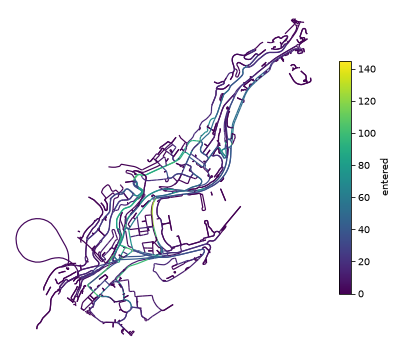

In [7]:
net.driving.map(color_by=cars)    # the edges colored by the number of cars (a picture here; live when you run it)

## MATSim

The id of each MATSim link is the `edge_id` too. `edge_map` reads `network.xml` and `network.xml.gz`.

In [8]:
net.driving.to_matsim("out/matsim_network.xml.gz")                     # the MATSim network
links = duckosm.sim.edge_map("out/matsim_network.xml.gz")              # the link id and the edge_id of each link
len(links), set(links.edge_id) == set(net.edges().edge_id)             # one link for each edge

MATSim out/matsim_network.xml.gz: done in 0.1 s

(2840, True)